## Practica 2
### Autores: Taha Ridda & Andrés Falcón

En esta practica, se haran... 

Para empezar, se tomaran la informacion de data.csv

In [267]:
import numpy as np 
import pandas as pd
import matplotlib as pl
import seaborn as sb


print("Datos contenedores del data.csv:")

data_csv = pd.read_csv("data.csv")

print(data_csv.head())

Datos contenedores del data.csv:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  

# ¿Cuántas viviendas hay en el conjunto de datos? Muestra las variables, si las hay, que tienen valores nulos e indica cuántos nulos tiene cada una de ellas.

In [268]:
print("Filas y columnas:", data_csv.shape)
print("Viviendas:", len(data_csv))

Filas y columnas: (1460, 81)
Viviendas: 1460


In [269]:
n_antes = len(data_csv)
nulos_antes = data_csv.isnull().sum()
nulos_antes = nulos_antes[nulos_antes > 0]
data_original = data_csv.copy()

print("Columnas con nulos:", len(nulos_antes))
print(nulos_antes)

Columnas con nulos: 19
LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


# 4. Realiza un estudio individual de las siguientes variables del conjunto de datos

### Id:

In [270]:
"""
• Identifica valores únicos de la columna
• El tipo (categórica sin orden, categórica con orden, discreto o continuo).
• Si hay valores nulos o no (puedes utilizar la salida de la pregunta 3 o buscar
específicamente en la columna a tratar).
• En caso de que la columna tenga valores nulos, el tratamiento que se te
ocurre para trabajar con ellos.
• Si la columna es numérica obtén valores mínimo y máximo; estudia si hay
outliers.
• Especifica si decides o no eliminar la columna, porque su aportación puede
ser irrelevante en procesos de modelado posteriores.• Si es necesaria una recodificación de la columna, por ser categórica u otra
razón, explica por qué se hace esta conversión y qué método empleas para
llevarla a cabo.
"""

print(data_csv['Id'].dtype)
print(data_csv['Id'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['Id'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['Id'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['Id'].isnull().sum()}")


print(data_csv['Id'].describe())
q1 = data_csv['Id'].quantile(0.25)
q3 = data_csv['Id'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr


outliers = data_csv[(data_csv['Id'] < inferior) | (data_csv['Id'] > superior)]
print(f"Se han conseguido {len(outliers)} outliers")
print(outliers[['Id', 'MoSold', 'SalePrice']].sort_values('Id'))


int64
1460

Imprimir valores unicos
---------------------------------------------------------
[   1    2    3 ... 1458 1459 1460]

Imprimir sus frecuencias unicos
-------------------------------------------------
Id
1       1
2       1
3       1
4       1
5       1
       ..
1456    1
1457    1
1458    1
1459    1
1460    1
Name: count, Length: 1460, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
count    1460.000000
mean      730.500000
std       421.610009
min         1.000000
25%       365.750000
50%       730.500000
75%      1095.250000
max      1460.000000
Name: Id, dtype: float64
Se han conseguido 0 outliers
Empty DataFrame
Columns: [Id, MoSold, SalePrice]
Index: []


Con esto, sabemos que:

- Los valores unicos de la columna son todos, 1460 numeros ints.
- El tipo es de categorica sin, ya que son valores de identificacion (aunque seo tampoco seria categorica porque cada uno es diferente)
- No tiene valores nulos
- La columna no es numerica, asi que aunque los valores son:
    - max: 1460
    - min: 1
    - Se encontraron 0 Outliers, ya que al ser tendencia lineal ningun valor se sale del patron
- Se puede ver que estos calculos son innecesarios
- Como son identificadores, no hace falta recodificacion.



### MSSubClass

In [271]:
print(data_csv['MSSubClass'].dtype)
print(data_csv['MSSubClass'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['MSSubClass'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['MSSubClass'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantmSSubClassad de valores nulos son: {data_csv['MSSubClass'].isnull().sum()}")


print(data_csv['MSSubClass'].describe())
q1 = data_csv['MSSubClass'].quantile(0.25)
q3 = data_csv['MSSubClass'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr


outliers = data_csv[(data_csv['MSSubClass'] < inferior) | (data_csv['MSSubClass'] > superior)]
print(f"Se han consegumSSubClasso {len(outliers)} outliers")
print(outliers[['MSSubClass', 'MoSold', 'SalePrice']].sort_values('MSSubClass'))


int64
15

Imprimir valores unicos
---------------------------------------------------------
[ 60  20  70  50 190  45  90 120  30  85  80 160  75 180  40]

Imprimir sus frecuencias unicos
-------------------------------------------------
MSSubClass
20     536
60     299
50     144
120     87
30      69
160     63
70      60
80      58
90      52
190     30
85      20
75      16
45      12
180     10
40       4
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantmSSubClassad de valores nulos son: 0
count    1460.000000
mean       56.897260
std        42.300571
min        20.000000
25%        20.000000
50%        50.000000
75%        70.000000
max       190.000000
Name: MSSubClass, dtype: float64
Se han consegumSSubClasso 103 outliers
      MSSubClass  MoSold  SalePrice
56           160       8     172500
87           160       6     164500
115          160       6     176000
225          160       5     112000
193          1

Con esto, sabemos que:

- Los valores unicos de la columna son 15 numeros ints.
- El tipo a primera vista parece numerica discreta, pero como cada numero lo que representa es un tipo de vivienda que no se comparan mediblemente entre si, deberiaes de categorica sin orden. 
- No tiene valores nulos
- La columna aunque no es numerica, se pueden calcular sus valores son:
    - max: 190
    - min: 20
    - Se encontraron 103 Outliers, lo que tiene sentido ya que estos valores no siguen un patron numerico real
- Aunque tienen valor numericos, al ser categorica hace falta la recodificacion ya que la maquina podra entenderlos y  se elimina la columna.



In [272]:
pd.get_dummies(data_csv, columns=['MSSubClass']).head()

,Id,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90,MSSubClass_120,MSSubClass_160,MSSubClass_180,MSSubClass_190
0,1,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,True,False,False,False,False,False,False,False,False,False
1,2,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,False,False,False,False,False,False,False,False,False,False
2,3,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,True,False,False,False,False,False,False,False,False,False
3,4,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,False,True,False,False,False,False,False,False,False,False
4,5,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,True,False,False,False,False,False,False,False,False,False


### MSZoning

In [273]:
print(data_csv['MSZoning'].dtype)
print(data_csv['MSZoning'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['MSZoning'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['MSZoning'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['MSZoning'].isnull().sum()}")


print(data_csv['MSZoning'].describe())

str
5

Imprimir valores unicos
---------------------------------------------------------
<StringArray>
['RL', 'RM', 'C (all)', 'FV', 'RH']
Length: 5, dtype: str

Imprimir sus frecuencias unicos
-------------------------------------------------
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
count     1460
unique       5
top         RL
freq      1151
Name: MSZoning, dtype: object


Con esto, sabemos que:

- Los valores unicos de la columna son 5 valores string.
- El tipo a es categorica sin orden, ya que no hay comparasion medible entre cada una. 
- No tiene valores nulos
- La columna aunque no es numerica, asi que no se pueden calcular sus valores min, max o outlier.
- Como no tienen valor numericos, hace falta la recodificacion y eliminar su columna original para evitar redundancia.



In [274]:
pd.get_dummies(data_csv, columns=['MSZoning']).head()

,Id,MSSubClass,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,MoSold,YrSold,SaleType,SaleCondition,SalePrice,MSZoning_C (all),MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM
0,1,60,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,2,2008,WD,Normal,208500,False,False,False,True,False
1,2,20,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,5,2007,WD,Normal,181500,False,False,False,True,False
2,3,60,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,9,2008,WD,Normal,223500,False,False,False,True,False
3,4,70,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,2,2006,WD,Abnorml,140000,False,False,False,True,False
4,5,60,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,12,2008,WD,Normal,250000,False,False,False,True,False


### LotFrontage

In [275]:
print(data_csv['LotFrontage'].dtype)
print(data_csv['LotFrontage'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['LotFrontage'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['LotFrontage'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['LotFrontage'].isnull().sum()}")


print(f"No creo que de valor valido: {data_csv['LotFrontage'].max()}")
print(data_csv['LotFrontage'].describe())

q1 = data_csv['LotFrontage'].quantile(0.25)
q3 = data_csv['LotFrontage'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr


outliers = data_csv[(data_csv['LotFrontage'] < inferior) | (data_csv['LotFrontage'] > superior)]
print(f"Se han consegulotFrontageo {len(outliers)} outliers")
print(outliers[['LotFrontage', 'MoSold', 'SalePrice']].sort_values('LotFrontage'))


float64
110

Imprimir valores unicos
---------------------------------------------------------
[ 65.  80.  68.  60.  84.  85.  75.  nan  51.  50.  70.  91.  72.  66.
 101.  57.  44. 110.  98.  47. 108. 112.  74. 115.  61.  48.  33.  52.
 100.  24.  89.  63.  76.  81.  95.  69.  21.  32.  78. 121. 122.  40.
 105.  73.  77.  64.  94.  34.  90.  55.  88.  82.  71. 120. 107.  92.
 134.  62.  86. 141.  97.  54.  41.  79. 174.  99.  67.  83.  43. 103.
  93.  30. 129. 140.  35.  37. 118.  87. 116. 150. 111.  49.  96.  59.
  36.  56. 102.  58.  38. 109. 130.  53. 137.  45. 106. 104.  42.  39.
 144. 114. 128. 149. 313. 168. 182. 138. 160. 152. 124. 153.  46.]

Imprimir sus frecuencias unicos
-------------------------------------------------
LotFrontage
60.0     143
70.0      70
80.0      69
50.0      57
75.0      53
        ... 
138.0      1
160.0      1
152.0      1
153.0      1
46.0       1
Name: count, Length: 110, dtype: int64

Imprimir booleano de si es nulo
-------------------------------

Con esto, sabemos que:

- Los valores unicos de la columna son 110 numeros.
- El tipo es numerica continua. 
- Tiene 259 valores nulos
- La columna aunque tenga nulos, se pueden calcular sus valores min, max o outlier:
    - max: 313
    - min: 21
    - outliers: 88
- Como tienen valor numericos, no hace falta la recodificacion o eliminar su columna original para evitar redundancia.



### LotArea

In [276]:
print(data_csv['LotArea'].dtype)
print(data_csv['LotArea'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['LotArea'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['LotArea'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['LotArea'].isnull().sum()}")


print(data_csv['LotArea'].describe())
q1 = data_csv['LotArea'].quantile(0.25)
q3 = data_csv['LotArea'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr


outliers = data_csv[(data_csv['LotArea'] < inferior) | (data_csv['LotArea'] > superior)]
print(f"Se han consegulotAreao {len(outliers)} outliers")
print(outliers[['LotArea', 'MoSold', 'SalePrice']].sort_values('LotArea'))


int64
1073

Imprimir valores unicos
---------------------------------------------------------
[ 8450  9600 11250 ... 17217 13175  9717]

Imprimir sus frecuencias unicos
-------------------------------------------------
LotArea
7200     25
9600     24
6000     17
10800    14
9000     14
         ..
26142     1
9262      1
17217     1
13175     1
9717      1
Name: count, Length: 1073, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
count      1460.000000
mean      10516.828082
std        9981.264932
min        1300.000000
25%        7553.500000
50%        9478.500000
75%       11601.500000
max      215245.000000
Name: LotArea, dtype: float64
Se han consegulotAreao 69 outliers
      LotArea  MoSold  SalePrice
956      1300       5     124000
1039     1477       4      80000
1151    17755      11     149900
1277    17871       6     197900
854     17920       7     170000
...       ...     ...        ...
45

Con esto, sabemos que:

- Los valores unicos de la columna son 1073 numeros.
- El tipo es numerica continua, ya que no tiene limites de rangos. 
- Tiene 0 valores nulos
- La columna aunque tenga nulos, se pueden calcular sus valores min, max o outlier:
    - max: 215245
    - min: 1300
    - outliers: 69
- Como tienen valor numericos, no hace falta la recodificacion o eliminar su columna original para evitar redundancia.



### Street

In [277]:
print(data_csv['Street'].dtype)
print(data_csv['Street'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['Street'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['Street'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['Street'].isnull().sum()}")


print(f"No creo que de valor valido: {data_csv['Street'].max()}")
print(data_csv['Street'].describe())

str
2

Imprimir valores unicos
---------------------------------------------------------
<StringArray>
['Pave', 'Grvl']
Length: 2, dtype: str

Imprimir sus frecuencias unicos
-------------------------------------------------
Street
Pave    1454
Grvl       6
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
No creo que de valor valido: Pave
count     1460
unique       2
top       Pave
freq      1454
Name: Street, dtype: object


Con esto, sabemos que:

- Los valores unicos de la columna son dos strings 
- El tipo es de categorica sin orden
- No tiene valores nulos
- La columna no es numerica, asi que no hay que calcular minimo ni maximo.

Como 'Street' es una columna de tipo categorica, ya que tiene solo dos strings que no se pueden medir o comparar entre si, es necesaria la recodificacion para que sea util en un machine learning. Se puede crear una nueva columnas, que muestren un 1 si tienen los valores 'Pave' u un 0 para cuanto tienen el valor 'Grvl'. Aunque deberian haber mas valores 'Grvl' o 'Pave', como no aparecieron en el data.csv podemos crear la tabla considerando solo estos dos valores para el proposito explicito de analizacion. 

In [278]:
pd.get_dummies(data_csv, columns=['Street'], drop_first=True).head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,Street_Pave
0,1,60,RL,65.0,8450,NaN,Reg,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,2,2008,WD,Normal,208500,True
1,2,20,RL,80.0,9600,NaN,Reg,Lvl,AllPub,FR2,...,NaN,NaN,NaN,0,5,2007,WD,Normal,181500,True
2,3,60,RL,68.0,11250,NaN,IR1,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,9,2008,WD,Normal,223500,True
3,4,70,RL,60.0,9550,NaN,IR1,Lvl,AllPub,Corner,...,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000,True
4,5,60,RL,84.0,14260,NaN,IR1,Lvl,AllPub,FR2,...,NaN,NaN,NaN,0,12,2008,WD,Normal,250000,True


### Alley

In [279]:
print(data_csv['Alley'].dtype)
print(data_csv['Alley'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['Alley'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['Alley'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['Alley'].isnull().sum()}")


print(f"No creo que de valor valido: {data_csv['Alley'].max()}")
print(data_csv['Alley'].describe())

str
2

Imprimir valores unicos
---------------------------------------------------------
<StringArray>
[nan, 'Grvl', 'Pave']
Length: 3, dtype: str

Imprimir sus frecuencias unicos
-------------------------------------------------
Alley
Grvl    50
Pave    41
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 1369
No creo que de valor valido: Pave
count       91
unique       2
top       Grvl
freq        50
Name: Alley, dtype: object


Con esto, sabemos que:

- Los valores unicos de la columna son 2 strings.
- El tipo es categorica sin orden, ya que no tiene limites de rangos. 
- Tiene 1369 valores nulos
- La columna no se puede calcular min o max
- Como no tienen valor numericos hace falta la recodificacion o eliminar su columna original para evitar redundancia.


In [280]:
pd.get_dummies(data_csv, columns=['Alley']).head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,...,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,Alley_Grvl,Alley_Pave
0,1,60,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,...,NaN,NaN,0,2,2008,WD,Normal,208500,False,False
1,2,20,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,...,NaN,NaN,0,5,2007,WD,Normal,181500,False,False
2,3,60,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,...,NaN,NaN,0,9,2008,WD,Normal,223500,False,False
3,4,70,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,...,NaN,NaN,0,2,2006,WD,Abnorml,140000,False,False
4,5,60,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,...,NaN,NaN,0,12,2008,WD,Normal,250000,False,False


### LotShape

In [281]:
print(data_csv['LotShape'].dtype)
print(data_csv['LotShape'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['LotShape'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['LotShape'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['LotShape'].isnull().sum()}")


print(f"No creo que de valor valido: {data_csv['LotShape'].max()}")
print(data_csv['LotShape'].describe())

str
4

Imprimir valores unicos
---------------------------------------------------------
<StringArray>
['Reg', 'IR1', 'IR2', 'IR3']
Length: 4, dtype: str

Imprimir sus frecuencias unicos
-------------------------------------------------
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
No creo que de valor valido: Reg
count     1460
unique       4
top        Reg
freq       925
Name: LotShape, dtype: object


Con esto, sabemos que:

- Los valores unicos de la columna son 4 strings
- El tipo es de categorica con orden, ya que se pueden comparar y medir segun su irregularidad.
- No tiene valores nulos
- La columna no es numerica, asi que no vale la pena conseguir max o min.

Como 'LotShape' es una columna de tipo categorica con orden, es necesaria la recodificacion para que sea util en un machine learning. Se puede asignar cada string con un numero especifico de mayor valoracion que el otro para representar el peso. Podemos hacer que cada una tenga un numero que vaya aumentando con su irregularidad.

Podemos eliminar la columna original para evitar redundancia

In [282]:
mapa_lots_shape = {'Reg': 0, 'IR1': 1, 'IR2': 2, 'IR3': 3}
data_csv['LotShape'] = data_csv['LotShape'].map(mapa_lots_shape)

### LandContour

In [283]:
print(data_csv['LandContour'].dtype)
print(data_csv['LandContour'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['LandContour'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['LandContour'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['LandContour'].isnull().sum()}")


print(f"No creo que de valor valido: {data_csv['LandContour'].max()}")
print(data_csv['LandContour'].describe())

str
4

Imprimir valores unicos
---------------------------------------------------------
<StringArray>
['Lvl', 'Bnk', 'Low', 'HLS']
Length: 4, dtype: str

Imprimir sus frecuencias unicos
-------------------------------------------------
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
No creo que de valor valido: Lvl
count     1460
unique       4
top        Lvl
freq      1311
Name: LandContour, dtype: object


Con esto, sabemos que:

- Los valores unicos de la columna son 4 strings
- A primera vista parece que el tipo es de categorica con orden, ya que se pueden comparar y medir segun su nivel de flatness/perpendicularidad. Pero valores como low: depression o el hecho de que Bnk y Hls tienen flatness no mas o menos, sino distinta, significa que solo puede ser categorica sin orden.
- No tiene valores nulos
- La columna no es numerica, asi que no vale la pena conseguir max o min.

Como 'LandCountour' es una columna de tipo categorica sin orden, es necesaria la recodificacion para que sea util en un machine learning. 



In [284]:
pd.get_dummies(data_csv, columns=['LandContour']).head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,Utilities,LotConfig,...,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,LandContour_Bnk,LandContour_HLS,LandContour_Low,LandContour_Lvl
0,1,60,RL,65.0,8450,Pave,NaN,0,AllPub,Inside,...,0,2,2008,WD,Normal,208500,False,False,False,True
1,2,20,RL,80.0,9600,Pave,NaN,0,AllPub,FR2,...,0,5,2007,WD,Normal,181500,False,False,False,True
2,3,60,RL,68.0,11250,Pave,NaN,1,AllPub,Inside,...,0,9,2008,WD,Normal,223500,False,False,False,True
3,4,70,RL,60.0,9550,Pave,NaN,1,AllPub,Corner,...,0,2,2006,WD,Abnorml,140000,False,False,False,True
4,5,60,RL,84.0,14260,Pave,NaN,1,AllPub,FR2,...,0,12,2008,WD,Normal,250000,False,False,False,True


### Utilities

In [285]:
"""
• Identifica valores únicos de la columna
• El tipo (categórica sin orden, categórica con orden, discreto o continuo).
• Si hay valores nulos o no (puedes utilizar la salida de la pregunta 3 o buscar específicamente en la columna a tratar).
• En caso de que la columna tenga valores nulos, el tratamiento que se te ocurre para trabajar con ellos.
• Si la columna es numérica obtén valores mínimo y máximo; estudia si hay outliers.
• Especifica si decides o no eliminar la columna, porque su aportación puede ser irrelevante en procesos de modelado posteriores.
• Si es necesaria una recodificación de la columna, por ser categórica u otra 
  razón, explica por qué se hace esta conversión y qué método empleas para llevarla a cabo.
"""

print(data_csv['Utilities'].dtype)
print(data_csv['Utilities'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['Utilities'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['Utilities'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['Utilities'].isnull().sum()}")


print(f"No creo que de valor valido: {data_csv['Utilities'].max()}")
print(data_csv['Utilities'].describe())


str
2

Imprimir valores unicos
---------------------------------------------------------
<StringArray>
['AllPub', 'NoSeWa']
Length: 2, dtype: str

Imprimir sus frecuencias unicos
-------------------------------------------------
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
No creo que de valor valido: NoSeWa
count       1460
unique         2
top       AllPub
freq        1459
Name: Utilities, dtype: object


Con esto, sabemos que:

- Los valores unicos de la columna son dos strings 'AllPub' y 'NoSeWa'
- El tipo es de categorica sin orden
- No tiene valores nulos
- La columna no es numerica, asi que no hay que calcular minimo ni maximo.

Como 'Utilities' es una columna de tipo categorica, ya que tiene solo dos strings que no se pueden medir o comparar entre si, es necesaria la recodificacion para que sea util en un machine learning. Se puede crear una nueva columnas, que muestren un 1 si tienen los valores 'AllPub' u un 0 para cuanto tienen el valor 'NoSeWa'. Aunque deberian haber mas valores 'NoSeWa' o 'ELO', como no aparecieron en el data.csv podemos crear la tabla considerando solo estos dos valores para el proposito explicito de analizacion. 

In [286]:
pd.get_dummies(data_csv, columns=['Utilities'], drop_first=True).head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,Utilities_NoSeWa
0,1,60,RL,65.0,8450,Pave,NaN,0,Lvl,Inside,...,NaN,NaN,NaN,0,2,2008,WD,Normal,208500,False
1,2,20,RL,80.0,9600,Pave,NaN,0,Lvl,FR2,...,NaN,NaN,NaN,0,5,2007,WD,Normal,181500,False
2,3,60,RL,68.0,11250,Pave,NaN,1,Lvl,Inside,...,NaN,NaN,NaN,0,9,2008,WD,Normal,223500,False
3,4,70,RL,60.0,9550,Pave,NaN,1,Lvl,Corner,...,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000,False
4,5,60,RL,84.0,14260,Pave,NaN,1,Lvl,FR2,...,NaN,NaN,NaN,0,12,2008,WD,Normal,250000,False


### LandSlope

In [287]:
print(data_csv['LandSlope'].dtype)
print(data_csv['LandSlope'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['LandSlope'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['LandSlope'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['LandSlope'].isnull().sum()}")

print(data_csv['LandSlope'].describe())


str
3

Imprimir valores unicos
---------------------------------------------------------
<StringArray>
['Gtl', 'Mod', 'Sev']
Length: 3, dtype: str

Imprimir sus frecuencias unicos
-------------------------------------------------
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
count     1460
unique       3
top        Gtl
freq      1382
Name: LandSlope, dtype: object


Con esto, sabemos que:

- Los valores unicos de la columna son dos strings ['Gtl', 'Mod', 'Sev']
- El tipo es de categorica con orden, ya que segun su definicion se pueden escalar como: {Gtl: Gentle slope, Mod: Moderate Slope, Sev: Severe Slope}. Por lo que podemos asignarlo a numeros, ya que sigue un orden.
- No tiene valores nulos
- La columna no es numerica, asi que no vale la pena conseguir max o min.

Como 'LandSlope' es una columna de tipo categorica con orden, es necesaria la recodificacion para que sea util en un machine learning. Se puede asignar cada string con un numero especifico de mayor valoracion que el otro para representar el peso. Podemos hacer que Sev=2, Mod=1 y Gtl=0, para representar la inclinacion o "Slope" encontrado en la columna, incrementando el valor mientras mas notable sea la inclinación.

No eliminaremos la columna original para tener una mejor grafica cuando hagamos el ejercicio 6.

In [288]:
mapa_land_slope = {'Gtl': 0, 'Mod': 1, 'Sev': 2}
data_csv['LandSlope_new'] = data_csv['LandSlope'].map(mapa_land_slope)

### Neighborhood
------------

In [289]:
print(data_csv['Neighborhood'].dtype)
print(data_csv['Neighborhood'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['Neighborhood'].unique())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['Neighborhood'].isnull().sum()}")


print(data_csv['Neighborhood'].describe())


str
25

Imprimir valores unicos
---------------------------------------------------------
<StringArray>
['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst',  'NWAmes',
 'OldTown', 'BrkSide',  'Sawyer', 'NridgHt',   'NAmes', 'SawyerW',  'IDOTRR',
 'MeadowV', 'Edwards',  'Timber', 'Gilbert', 'StoneBr', 'ClearCr', 'NPkVill',
 'Blmngtn',  'BrDale',   'SWISU', 'Blueste']
Length: 25, dtype: str

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
count      1460
unique       25
top       NAmes
freq        225
Name: Neighborhood, dtype: object


Con esto, sabemos que:

- Los valores unicos de la columna son 25 strings que representan ubicaciones.
- El tipo es de categorica sin orden, ya que no hay comparacion entre cada una.
- No tiene valores nulos
- La columna no es numerica, asi que no vale la pena conseguir max o min.

Como 'Neighborhood' es una columna de tipo categorica sin orden, es necesaria la recodificacion para que sea util en un machine learning. 

In [290]:
pd.get_dummies(data_csv, columns=['Neighborhood']).head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker
0,1,60,RL,65.0,8450,Pave,NaN,0,Lvl,AllPub,...,False,False,False,False,False,False,False,False,False,False
1,2,20,RL,80.0,9600,Pave,NaN,0,Lvl,AllPub,...,False,False,False,False,False,False,False,False,False,True
2,3,60,RL,68.0,11250,Pave,NaN,1,Lvl,AllPub,...,False,False,False,False,False,False,False,False,False,False
3,4,70,RL,60.0,9550,Pave,NaN,1,Lvl,AllPub,...,False,False,False,False,False,False,False,False,False,False
4,5,60,RL,84.0,14260,Pave,NaN,1,Lvl,AllPub,...,True,False,False,False,False,False,False,False,False,False


### YearBuilt

In [291]:
print(data_csv['YearBuilt'].dtype)
print(data_csv['YearBuilt'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['YearBuilt'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['YearBuilt'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['YearBuilt'].isnull().sum()}")


print(data_csv['YearBuilt'].describe())


int64
112

Imprimir valores unicos
---------------------------------------------------------
[2003 1976 2001 1915 2000 1993 2004 1973 1931 1939 1965 2005 1962 2006
 1960 1929 1970 1967 1958 1930 2002 1968 2007 1951 1957 1927 1920 1966
 1959 1994 1954 1953 1955 1983 1975 1997 1934 1963 1981 1964 1999 1972
 1921 1945 1982 1998 1956 1948 1910 1995 1991 2009 1950 1961 1977 1985
 1979 1885 1919 1990 1969 1935 1988 1971 1952 1936 1923 1924 1984 1926
 1940 1941 1987 1986 2008 1908 1892 1916 1932 1918 1912 1947 1925 1900
 1980 1989 1992 1949 1880 1928 1978 1922 1996 2010 1946 1913 1937 1942
 1938 1974 1893 1914 1906 1890 1898 1904 1882 1875 1911 1917 1872 1905]

Imprimir sus frecuencias unicos
-------------------------------------------------
YearBuilt
2006    67
2005    64
2004    54
2007    49
2003    45
        ..
1875     1
1911     1
1917     1
1872     1
1905     1
Name: count, Length: 112, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La

Con esto, sabemos que:

- Los valores unicos de la columna son 112 numeros ints que representan fechas/años.
- El tipo es de numerica discreta, ya que son fechas que no incluyen decimales o separaciones con posibilidades infinitas.
- No tiene valores nulos
- La columna no es numerica, asi que los valores son:
- - max: 2010
- - min: 1872

In [292]:
print(f"Valores Originales {len(data_csv['YearBuilt'])} outliers")

q1 = data_csv['YearBuilt'].quantile(0.25)
q3 = data_csv['YearBuilt'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr

print(f"Q1: {q1} y Q3: {q3} Y iqr: {iqr}\n Superior: {superior} e Inferior: {inferior}")


outliers = data_csv[(data_csv['YearBuilt'] < inferior) | (data_csv['YearBuilt'] > superior)]
print(f"Se han conseguido {len(outliers)} outliers")
print(outliers[['Id', 'YearBuilt', 'SalePrice']].sort_values('YearBuilt'))

Valores Originales 1460 outliers
Q1: 1954.0 y Q3: 2000.0 Y iqr: 46.0
 Superior: 2069.0 e Inferior: 1885.0
Se han conseguido 7 outliers
        Id  YearBuilt  SalePrice
1349  1350       1872     122000
1137  1138       1875      94000
304    305       1880     295000
630    631       1880     124000
1132  1133       1880     117500
747    748       1880     265979
991    992       1882     168000


Como podemos ver, los unicos outliers del patron de las fechas son las fechas muy antiguas.

- Como tienen valor numericos, no hace falta la recodificacion, y no se elimina la columna.

### YearRemodAdd

In [293]:
print(data_csv['YearRemodAdd'].dtype)
print(data_csv['YearRemodAdd'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['YearRemodAdd'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['YearRemodAdd'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['YearRemodAdd'].isnull().sum()}")


print(data_csv['YearRemodAdd'].describe())


q1 = data_csv['YearRemodAdd'].quantile(0.25)
q3 = data_csv['YearRemodAdd'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr


outliers = data_csv[(data_csv['YearRemodAdd'] < inferior) | (data_csv['YearRemodAdd'] > superior)]
print(f"Se han conseguido {len(outliers)} outliers")
print(outliers[['Id', 'YearRemodAdd', 'SalePrice']].sort_values('YearRemodAdd'))

int64
61

Imprimir valores unicos
---------------------------------------------------------
[2003 1976 2002 1970 2000 1995 2005 1973 1950 1965 2006 1962 2007 1960
 2001 1967 2004 2008 1997 1959 1990 1955 1983 1980 1966 1963 1987 1964
 1972 1996 1998 1989 1953 1956 1968 1981 1992 2009 1982 1961 1993 1999
 1985 1979 1977 1969 1958 1991 1971 1952 1975 2010 1984 1986 1994 1988
 1954 1957 1951 1978 1974]

Imprimir sus frecuencias unicos
-------------------------------------------------
YearRemodAdd
1950    178
2006     97
2007     76
2005     73
2004     62
       ... 
2010      6
1983      5
1952      5
1986      5
1951      4
Name: count, Length: 61, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
count    1460.000000
mean     1984.865753
std        20.645407
min      1950.000000
25%      1967.000000
50%      1994.000000
75%      2004.000000
max      2010.000000
Name: YearRemodAdd, dtype: float64
Se han co

Con esto, sabemos que:

- Los valores unicos de la columna son 61 numeros ints que representan fechas/años.
- El tipo es de numerica discreta, ya que son fechas que no incluyen decimales.
- No tiene valores nulos
- La columna no es numerica, asi que los valores son:
    - max: 2010
    - min: 1950
    - No se encontro ningun Outlier
- Como tienen valor numericos, no hace falta la recodificacion, y no se elimina la columna.



### GarageCars, GarageArea, GarageQual, GarageCond, GarageType
### GarageYrBlt, GarageFinish (se recomienda analizarlas en conjunto)

In [294]:
options = ["GarageCars", "GarageArea", "GarageQual", "GarageCond", "GarageType", "GarageYrBlt", "GarageFinish"]

# Valores Unicos
types = ""
numniques = ""
uniques = []
nulos = ""
print(f"Para los valores {options}")
for i in options:
    print("----------------------------")
    print(f"Para el valor de {i}")
    #types += f"{data_csv[i].dtype}, "
    #numniques += f"{data_csv[i].nunique()}"
    #uniques.append(data_csv[i].unique())
    #nulos += f"{data_csv[i].isnull().sum()}"
    print(f"dtype : {data_csv[i].dtype}")
    print(f"nunique : {data_csv[i].nunique()}")
    print(f"nulos : {data_csv[i].isnull().sum()}")
    print(f"value_counts :")
    print(data_csv[i].value_counts().head(10))
    if pd.api.types.is_numeric_dtype(data_csv[i]):
        print(f"describe      :")
        print(data_csv[i].describe())
    print()

resumen = pd.DataFrame({
    'dtype':   [data_csv[c].dtype for c in options],
    'nunique': [data_csv[c].nunique() for c in options],
    'nulos':   [data_csv[c].isnull().sum() for c in options],
}, index=options)

print(resumen)



Para los valores ['GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'GarageType', 'GarageYrBlt', 'GarageFinish']
----------------------------
Para el valor de GarageCars
dtype : int64
nunique : 5
nulos : 0
value_counts :
GarageCars
2    824
1    369
3    181
0     81
4      5
Name: count, dtype: int64
describe      :
count    1460.000000
mean        1.767123
std         0.747315
min         0.000000
25%         1.000000
50%         2.000000
75%         2.000000
max         4.000000
Name: GarageCars, dtype: float64

----------------------------
Para el valor de GarageArea
dtype : int64
nunique : 441
nulos : 0
value_counts :
GarageArea
0      81
440    49
576    47
240    38
484    34
528    33
288    27
400    25
480    24
264    24
Name: count, dtype: int64
describe      :
count    1460.000000
mean      472.980137
std       213.804841
min         0.000000
25%       334.500000
50%       480.000000
75%       576.000000
max      1418.000000
Name: GarageArea, dtype: float64

--------

Con esto, sabemos que:

- La mayoria de los valores unicos de las columnas son 562 valores que varian entre numeros, numeros decimales y strings.
- Los tipos dependen de Categorica sin orden, categorica con orden, numerica decimal y numerica continua.
- Entre todos tienen 405 valores nulos, los cuales vienen del mismo conjunto de filas y corresponden a viviendas sin garaje (GarageCars=0, GarageArea=0)
- No se pueden calcular los valores max o min de todo el conjunto ya que son valores/tipos distintos.

- Solo se pueden recodificar los valores que hacen falta:

In [295]:
for c in ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']:
    data_csv[c] = data_csv[c].fillna('NoGarage')

mapa_calidad = {'NoGarage': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
data_csv['GarageQual'] = data_csv['GarageQual'].map(mapa_calidad)
data_csv['GarageCond'] = data_csv['GarageCond'].map(mapa_calidad)
data_csv['GarageFinish'] = data_csv['GarageFinish'].map({'NoGarage': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})
data_csv = data_csv.drop(columns=['GarageYrBlt'])
data_csv = pd.get_dummies(data_csv, columns=['GarageType'])

### OverallQual

In [296]:
print(data_csv['OverallQual'].dtype)
print(data_csv['OverallQual'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['OverallQual'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['OverallQual'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['OverallQual'].isnull().sum()}")


print(data_csv['OverallQual'].describe())
q1 = data_csv['OverallQual'].quantile(0.25)
q3 = data_csv['OverallQual'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr


outliers = data_csv[(data_csv['OverallQual'] < inferior) | (data_csv['OverallQual'] > superior)]
print(f"Se han conseguido {len(outliers)} outliers")
print(outliers[['Id', 'OverallQual', 'SalePrice']].sort_values('OverallQual'))


int64
10

Imprimir valores unicos
---------------------------------------------------------
[ 7  6  8  5  9  4 10  3  1  2]

Imprimir sus frecuencias unicos
-------------------------------------------------
OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      20
10     18
2       3
1       2
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
count    1460.000000
mean        6.099315
std         1.382997
min         1.000000
25%         5.000000
50%         6.000000
75%         7.000000
max        10.000000
Name: OverallQual, dtype: float64
Se han conseguido 2 outliers
      Id  OverallQual  SalePrice
375  376            1      61000
533  534            1      39300


Con esto, sabemos que:

- Los valores unicos de la columna son 10 numeros ints entre 1 a 10.
- El tipo es de numerica discreta, ya que son valores que no incluyen decimales limitados del 1 al 10.
- No tiene valores nulos
- La columna no es numerica, asi que los valores son:
    - max: 10
    - min: 1
    - Se encontraron 2 Outliers: 1 y 1
- Como tienen valor numericos, no hace falta la recodificacion, y no se elimina la columna.



### OverallCond

In [297]:
print(data_csv['OverallCond'].dtype)
print(data_csv['OverallCond'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['OverallCond'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['OverallCond'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['OverallCond'].isnull().sum()}")


print(data_csv['OverallCond'].describe())
q1 = data_csv['OverallCond'].quantile(0.25)
q3 = data_csv['OverallCond'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr


outliers = data_csv[(data_csv['OverallCond'] < inferior) | (data_csv['OverallCond'] > superior)]
print(f"Se han conseguido {len(outliers)} outliers")
print(outliers[['Id', 'OverallCond', 'SalePrice']].sort_values('OverallCond'))


int64
9

Imprimir valores unicos
---------------------------------------------------------
[5 8 6 7 4 2 3 9 1]

Imprimir sus frecuencias unicos
-------------------------------------------------
OverallCond
5    821
6    252
7    205
8     72
4     57
3     25
9     22
2      5
1      1
Name: count, dtype: int64

Imprimir booleano de si es nulo
-------------------------------------------------
La cantidad de valores nulos son: 0
count    1460.000000
mean        5.575342
std         1.112799
min         1.000000
25%         5.000000
50%         5.000000
75%         6.000000
max         9.000000
Name: OverallCond, dtype: float64
Se han conseguido 125 outliers
        Id  OverallCond  SalePrice
375    376            1      61000
88      89            2      85000
250    251            2      76500
378    379            2     394432
398    399            2      67000
...    ...          ...        ...
1352  1353            9     134900
1327  1328            9     130500
1268  1269          

Con esto, sabemos que:

- Los valores unicos de la columna son 9 numeros ints.
- El tipo es de numerica discreta, ya que son valores que no incluyen decimales limitados del 1 al 9.
- No tiene valores nulos
- La columna no es numerica, asi que los valores son:
    - max: 9
    - min: 1
    - Se encontraron 125 Outliers.
- Como tienen valor numericos, no hace falta la recodificacion, y no se elimina la columna.



### SalePrice

In [298]:
print(data_csv['SalePrice'].dtype)
print(data_csv['SalePrice'].nunique())

print("\nImprimir valores unicos\n---------------------------------------------------------")
print(data_csv['SalePrice'].unique())

print("\nImprimir sus frecuencias unicos\n-------------------------------------------------")
print(data_csv['SalePrice'].value_counts())

print("\nImprimir booleano de si es nulo\n-------------------------------------------------")
print(f"La cantidad de valores nulos son: {data_csv['SalePrice'].isnull().sum()}")


print(data_csv['SalePrice'].describe())
q1 = data_csv['SalePrice'].quantile(0.25)
q3 = data_csv['SalePrice'].quantile(0.75)
iqr = q3 - q1

inferior = q1 - 1.5*iqr
superior = q3 + 1.5*iqr


outliers = data_csv[(data_csv['SalePrice'] < inferior) | (data_csv['SalePrice'] > superior)]
print(f"Se han conseguido {len(outliers)} outliers")
print(outliers[['Id', 'SalePrice', 'SaleType']].sort_values('SalePrice'))




int64
663

Imprimir valores unicos
---------------------------------------------------------
[208500 181500 223500 140000 250000 143000 307000 200000 129900 118000
 129500 345000 144000 279500 157000 132000 149000  90000 159000 139000
 325300 139400 230000 154000 256300 134800 306000 207500  68500  40000
 149350 179900 165500 277500 309000 145000 153000 109000  82000 160000
 170000 130250 141000 319900 239686 249700 113000 127000 177000 114500
 110000 385000 130000 180500 172500 196500 438780 124900 158000 101000
 202500 219500 317000 180000 226000  80000 225000 244000 185000 144900
 107400  91000 135750 136500 193500 153500 245000 126500 168500 260000
 174000 164500  85000 123600 109900  98600 163500 133900 204750 214000
  94750  83000 128950 205000 178000 118964 198900 169500 100000 115000
 190000 136900 383970 217000 259500 176000 155000 320000 163990 136000
 153900 181000  84500 128000  87000 150000 150750 220000 171000 231500
 166000 204000 125000 105000 222500 122000 372402 23500

Con esto, sabemos que:

- Los valores unicos de la columna son 663 numeros ints.
- El tipo es de numerica continua, ya que no tienen limites.
- No tiene valores nulos
- La columna no es numerica, asi que los valores son:
    - max: 755000
    - min: 34900
    - Se encontraron 61 Outliers.
- Como tienen valor numericos, no hace falta la recodificacion, y no se elimina la columna.



# 5. Ahora que has realizado algunas operaciones sobre las columnas anteriores, vamos a comprobar algunas estadísticas simples. Por ejemplo:

### Comprueba el número de casas. ¿Ha variado respecto del que calculaste en la pregunta 3?


In [299]:
print("Numero de casas antiguamente:", n_antes, "| numero de casas actualmente:", len(data_csv))

Numero de casas antiguamente: 1460 | numero de casas actualmente: 1460


### Comprueba de nuevo el número de valores nulos de las columnas. ¿Ha variado respecto al que obtuviste en la pregunta 3? Para facilitar esta respuesta rellena una tabla como la siguiente:

| Columna | #Missing values anteriores | #Missing values actual |
|------|-----|------|
|      |     |      |
|      |     |      |

In [300]:
tabla = pd.DataFrame({'#Missing values anteriores': nulos_antes})
tabla['#Missing values actual'] = [data_csv.filter(regex=f'^{c}').isnull().sum().sum() for c in tabla.index]
print(tabla)

              #Missing values anteriores  #Missing values actual
LotFrontage                          259                   259.0
Alley                               1369                  1369.0
MasVnrType                           872                   872.0
MasVnrArea                             8                     8.0
BsmtQual                              37                    37.0
BsmtCond                              37                    37.0
BsmtExposure                          38                    38.0
BsmtFinType1                          37                    37.0
BsmtFinType2                          38                    38.0
Electrical                             1                     1.0
FireplaceQu                          690                   690.0
GarageType                            81                     0.0
GarageYrBlt                           81                     0.0
GarageFinish                          81                     0.0
GarageQual               

# 6. Muestra un histograma de las variables LotFrontage, LotArea, SalePrice, OveralQual y comenta los resultados.
Crea un gráfico de donut para variables categóricas como LandSlope y, Neighborhood.

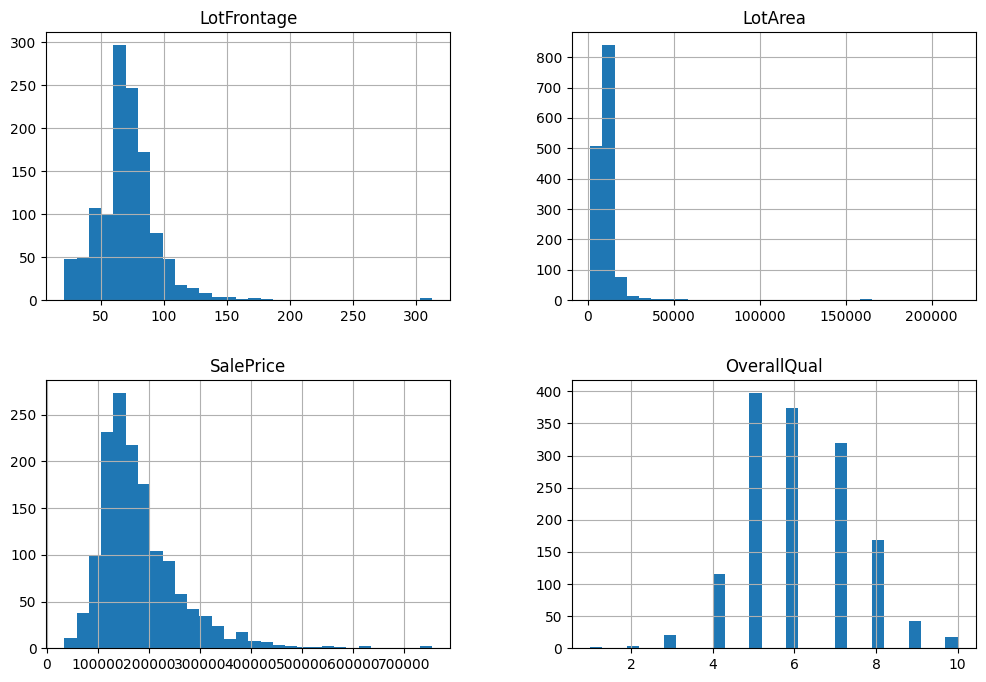

In [301]:
data_original[['LotFrontage', 'LotArea', 'SalePrice', 'OverallQual']].hist(bins=30, figsize=(12, 8))
pl.pyplot.show()

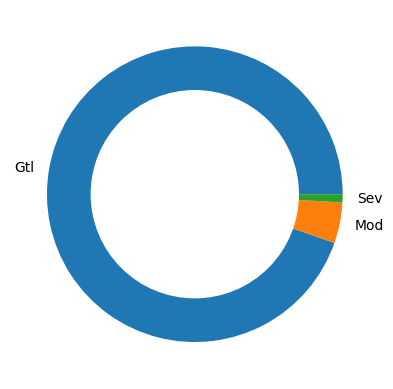

In [302]:
conteo = data_original['LandSlope'].value_counts()
pl.pyplot.pie(conteo, labels=conteo.index)
pl.pyplot.gca().add_artist(pl.pyplot.Circle((0, 0), 0.7, color='white'))
pl.pyplot.show()

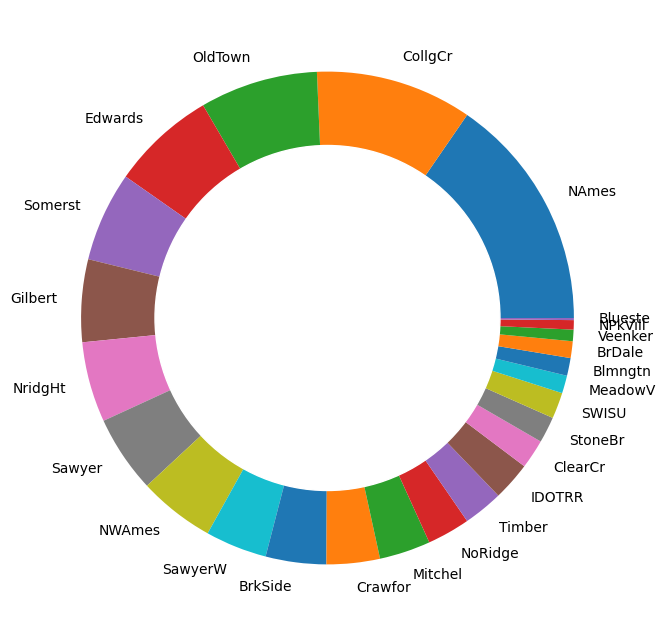

In [303]:
pl.pyplot.figure(figsize=(8, 8))
conteo = data_original['Neighborhood'].value_counts()
pl.pyplot.pie(conteo, labels=conteo.index)
pl.pyplot.gca().add_artist(pl.pyplot.Circle((0, 0), 0.7, color='white'))
pl.pyplot.show()

### A la vista de los resultados, ¿qué decisiones tomarías sobre estas tres variables?

Explicacion aqui...

# 7. Para finalizar, estudia la correlación entre las variables numéricas del dataset.
Calcula la matriz de correlación de estas variables y muéstrala con la función
clustermap de la librería seaborn. Comenta los resultados.

La matriz de correlación solo funcionara para las variables numericas que hemos calculado

                           Id  MSSubClass  LotFrontage   LotArea  LotShape  \
Id                   1.000000    0.011156    -0.010601 -0.033226 -0.024071   
MSSubClass           0.011156    1.000000    -0.386347 -0.139781 -0.115361   
LotFrontage         -0.010601   -0.386347     1.000000  0.426095  0.231878   
LotArea             -0.033226   -0.139781     0.426095  1.000000  0.315484   
LotShape            -0.024071   -0.115361     0.231878  0.315484  1.000000   
OverallQual         -0.028365    0.032628     0.251646  0.105806  0.198994   
OverallCond          0.012609   -0.059316    -0.059213 -0.005636 -0.033747   
YearBuilt           -0.012713    0.027850     0.123349  0.014228  0.229365   
YearRemodAdd        -0.021998    0.040581     0.088866  0.013788  0.175488   
MasVnrArea          -0.050298    0.022936     0.193458  0.104160  0.089178   
BsmtFinSF1          -0.005024   -0.069836     0.233633  0.214103  0.157718   
BsmtFinSF2          -0.005968   -0.065649     0.049900  0.111170

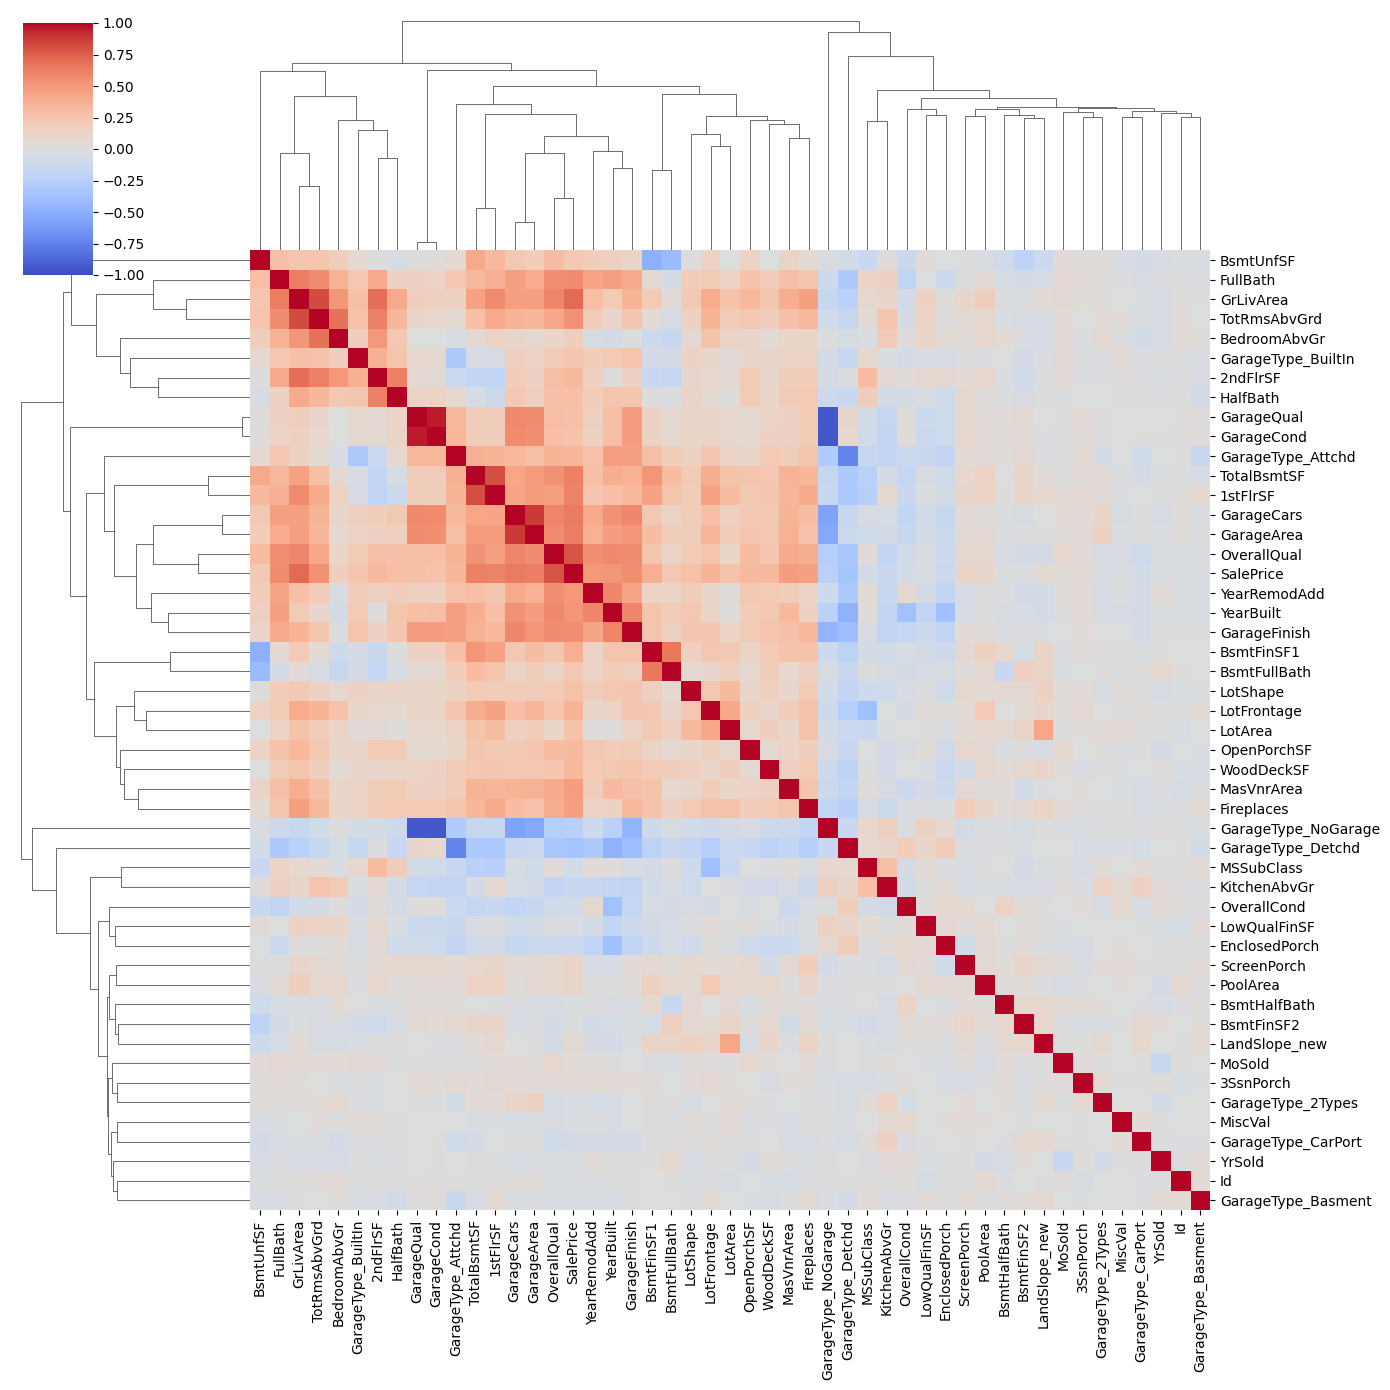

In [304]:
matriz_corr = data_csv.corr(numeric_only=True)
print(matriz_corr)

sb.clustermap(matriz_corr, figsize=(14, 14), cmap='coolwarm', center=0, vmin=-1, vmax=1, method='average', annot=False)
pl.pyplot.show()


El clustermap muestra bloques claros de variables muy correlacionadas entre sí, especialmente las de tamaño/superficie y con los garages (GrLivArea, 1stFlrSF, TotalBsmtSF, GarageArea, GarageCars) y las de calidad/antigüedad (OverallQual, YearBuilt, YearRemodAdd, GarageFinish), lo que indica una que habrá que tener en cuenta esos valores en los modelos de regresión que vendran a continuación.